### 4.4 Definição do Hardware

In [ ]:
# Verificar o status da GPU
!nvidia-smi

Wed Jun 10 15:52:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 4.5 Configuração do Ambiente (YOLOv8 e Dependências)

In [ ]:
# Instala o motor Ultralytics (que roda YOLOv8 e YOLO11)
!pip install ultralytics
import ultralytics

# Verifica se o Colab te deu a placa de vídeo (GPU)
ultralytics.checks()

### Conexão com a Nuvem (Google Drive)

In [ ]:
from google.colab import drive
import os

# Montar o Google Drive
drive.mount('/content/drive')

# Desmontar o Google Drive
# drive.flush_and_unmount()

Mounted at /content/drive


### 4.3 Pré-processamento dos Datasets (Pipeline MLOps Automático)

In [ ]:
import shutil
import yaml
import os

# 1. Caminhos
caminho_zip_drive = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Yolo_dataset.zip"
pasta_local_vm = "/content/Yolo_dataset"
yaml_path = f"{pasta_local_vm}/data.yaml"

# 2. Criar a pasta para não espalhar os arquivos
os.makedirs(pasta_local_vm, exist_ok=True)

# 3. Automação MLOps (Verifica se a pasta de imagens existe)
if not os.path.exists(f"{pasta_local_vm}/images"):
    print("🚚 1. Copiando o ZIP do Drive para o SSD da VM...")
    shutil.copy2(caminho_zip_drive, "/content/Yolo_dataset.zip")
    
    print("📦 2. Descompactando na velocidade da luz...")
    shutil.unpack_archive("/content/Yolo_dataset.zip", pasta_local_vm)
    print(" ✅ Descompactação concluída.")
else:
    print("✅ O dataset já está descompactado no SSD desta sessão!")

# 4. A Cirurgia do YAML (Só atua se o caminho estiver errado!)
if os.path.exists(yaml_path):
    with open(yaml_path, 'r') as f:
        data = yaml.safe_load(f)
    
    # Ele confere: O caminho atual já é o da VM local?
    if data.get('path') != pasta_local_vm:
        print("🔧 3. Ajustando o caminho no data.yaml existente...")
        data['path'] = pasta_local_vm
        with open(yaml_path, 'w') as f:
            yaml.dump(data, f, sort_keys=False)
        print(" 🚀 data.yaml atualizado com sucesso!")
else:
    print(" ⚠️ data.yaml não encontrado! O YOLO vai precisar dele para rodar.")

# 5. Aponta a variável global do YOLO para o SSD local
os.environ["DATASET_DIRECTORY"] = pasta_local_vm

🚚 1. Copiando o ZIP do Drive para o SSD da VM...
📦 2. Descompactando na velocidade da luz...
 ✅ Descompactação concluída.
🔧 3. Ajustando o caminho no data.yaml existente...
 🚀 data.yaml atualizado com sucesso!


### 4.6 Definição de Hiperparâmetros e 4.7 Treinamento do Modelo

In [ ]:
import os
from datetime import datetime

DATASET_DIRECTORY = "/content/Yolo_dataset" # Ajuste se sua pasta tiver outro nome

# 1. Limpeza de Cache (Segurança)
!rm -f "$DATASET_DIRECTORY/labels/train/*.cache"
!rm -f "$DATASET_DIRECTORY/labels/val/*.cache"

# 2. Desativa W&B
os.environ["WANDB_DISABLED"] = "true"
print("W&B desativado.")

# 3. Configura a nova casa no Drive
agora = datetime.now()
nome_treino_v8 = agora.strftime("Treino_v8_%Y-%m-%d_%Hh%M")
# Criei uma pasta "Resultados_YOLOv8" para não misturar com o v5
diretorio_drive_v8 = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv8"

os.environ["NOME_TREINO_V8"] = nome_treino_v8
os.environ["DIRETORIO_DRIVE_V8"] = diretorio_drive_v8

print(f"🚀 Iniciando YOLOv8. Salvando direto no Drive em: {diretorio_drive_v8}/{nome_treino_v8}")

# 4. O comando mágico do YOLOv8
!yolo train model=yolov8s.pt data="$DATASET_DIRECTORY/data.yaml" epochs=25 batch=64 project="$DIRETORIO_DRIVE_V8" name="$NOME_TREINO_V8" cache=True

### CÉLULA DE RETOMADA: SE OS CRÉDITOS ACABAREM 

In [ ]:
# Se a máquina cair, coloque o nome da pasta gerada aqui e rode esta célula:
nome_treino_parado = "Treino_v8_SUA_DATA_AQUI"
caminho_last_v8 = f"/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv8/{nome_treino_parado}/weights/last.pt"

print(f"🔄 Retomando o treino a partir de: {caminho_last_v8}")
!yolo train resume model="$caminho_last_v8"

### Backup de Treino (Salvamento dos Pesos)

In [ ]:
import shutil
import os

# 1. Recupera o nome exato que foi usado no treinamento
nome_treino = os.environ.get("NOME_TREINO", "exp")

# 2. Caminhos dinâmicos (Origem e Destino)
origem = f"/content/yolov5/runs/train/{nome_treino}"
destino = f"/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5/{nome_treino}"

# 3. Copia a pasta inteira, sobrescrevendo arquivos velhos se necessário
shutil.copytree(origem, destino, dirs_exist_ok=True)

print(f"✅ Todos os gráficos e o modelo foram salvos em: {destino}")

✅ Todos os gráficos e o modelo foram salvos em: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5/Treino_2026-06-10_15h54


### 4.7 Inferência com o Conjunto de Testes

In [ ]:
# Avalia o melhor peso do treino diretamente do seu Drive
!yolo val model="$DIRETORIO_DRIVE_V8/$NOME_TREINO_V8/weights/best.pt" data="$DATASET_DIRECTORY/data.yaml" split=test

### Backup do teste


In [ ]:
import shutil
import os

# 1. Recupera as variáveis de nome
nome_treino = os.environ.get("NOME_TREINO", "exp")
nome_teste = nome_treino.replace("Treino", "Teste")

# 2. Define a origem (VM) e o destino (Drive)
pasta_resultados_teste_vm = f"/content/yolov5/runs/val/{nome_teste}"
pasta_teste_drive = f"/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5/{nome_teste}"

print(f"💾 Iniciando backup da pasta de teste para o Google Drive...")

# 3. Executa a cópia de segurança
shutil.copytree(pasta_resultados_teste_vm, pasta_teste_drive, dirs_exist_ok=True)

print(f"✅ Backup concluído com sucesso!")
print(f"👉 Salvo em: {pasta_teste_drive}")

💾 Iniciando backup da pasta de teste para o Google Drive...
✅ Backup concluído com sucesso!
👉 Salvo em: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5/Teste_2026-06-10_15h54


### 4.8 Coleta De metricas visuais

📊 Lendo Métricas Oficiais direto do Google Drive...
------------------------------------------------------------
>>> MÉTRICAS DE TREINAMENTO (Acurácia e Loss)


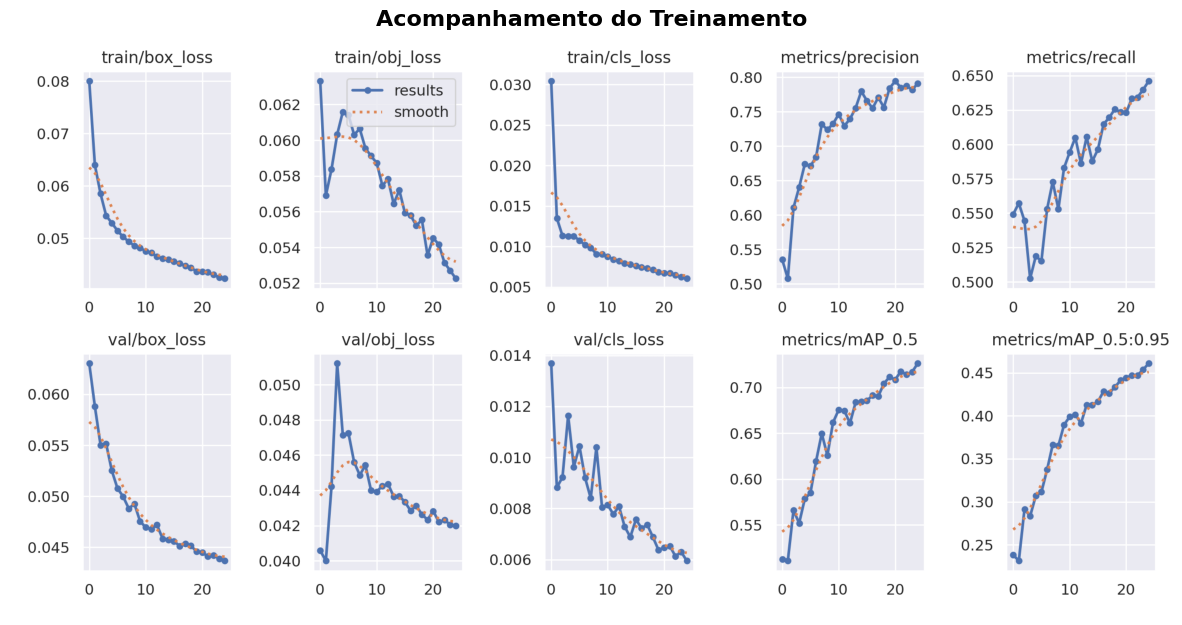


>>> MÉTRICAS DE TESTE (Avaliação Final)


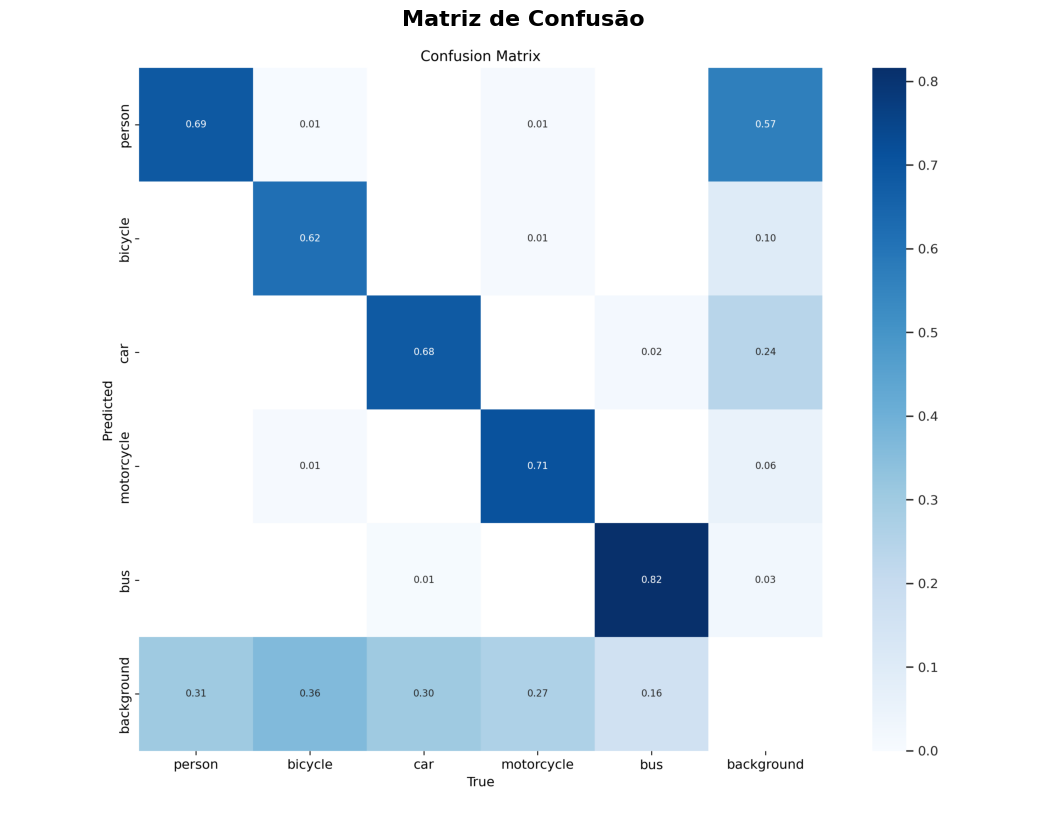

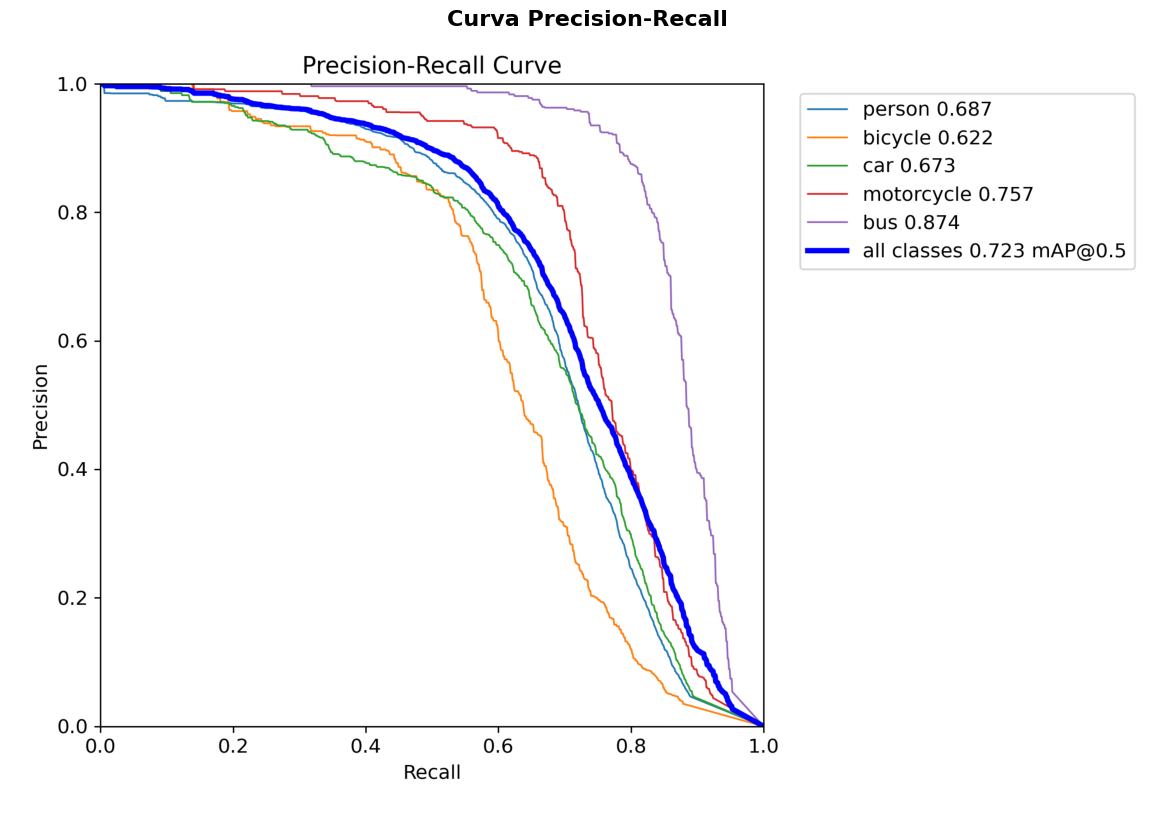


>>> INFERÊNCIA PRÁTICA (Ground Truth vs Predições)


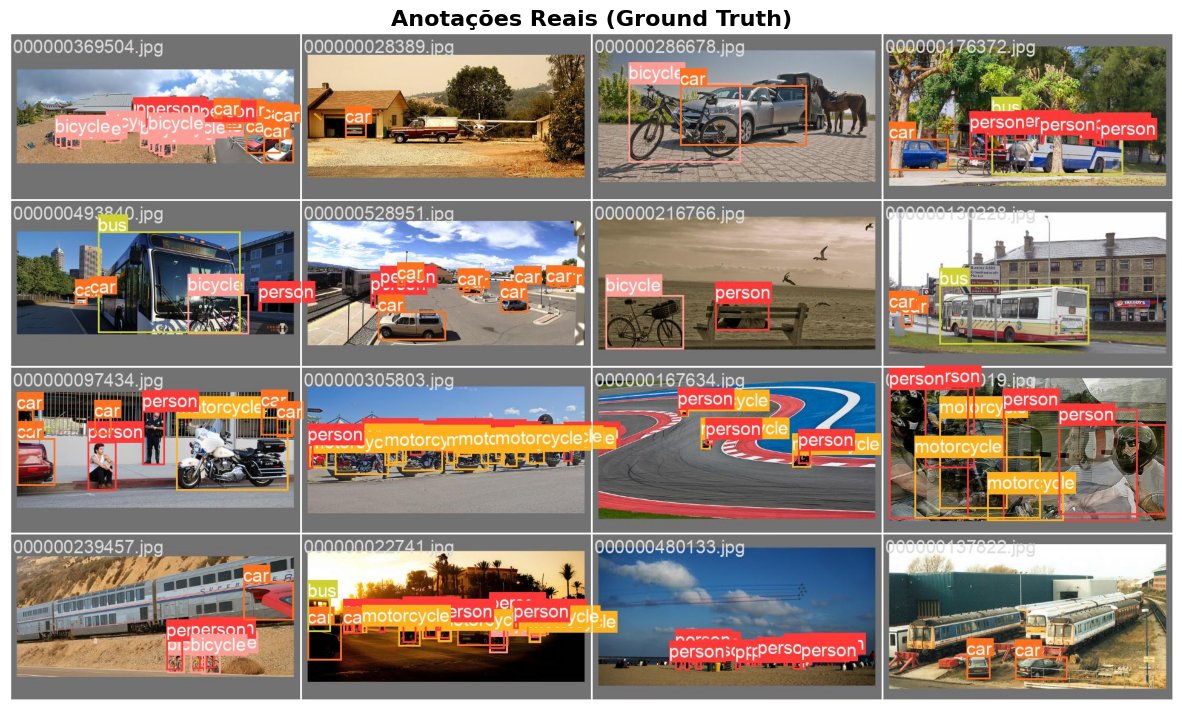

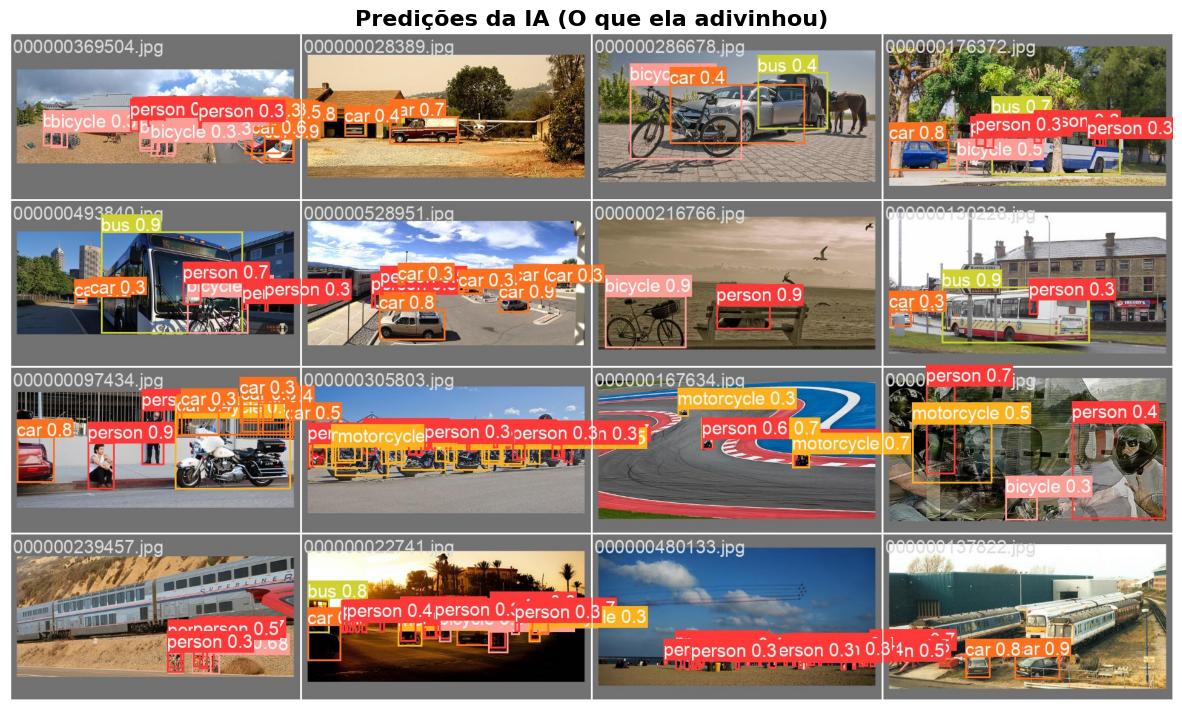


✅ Fluxo finalizado! O seu modelo está treinado, testado e com backup garantido.


In [ ]:
import matplotlib.pyplot as plt
import cv2
import os

def mostrar_metrica(caminho_imagem, titulo):
    """Lê uma imagem do disco e a exibe no Colab."""
    img = cv2.imread(caminho_imagem)
    if img is not None:
        plt.figure(figsize=(15, 10))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(titulo, fontsize=16, fontweight='bold')
        plt.axis('off')
        plt.show()
    else:
        print(f"⚠️ Métrica não encontrada no Drive: {caminho_imagem}")

# 1. Recupera os nomes
nome_treino = os.environ.get("NOME_TREINO", "exp")
nome_teste = nome_treino.replace("Treino", "Teste")

# 2. AGORA TUDO VEM DO SEU DRIVE! (Segurança Máxima)
pasta_treino_drive = f"/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5/{nome_treino}"
pasta_teste_drive = f"/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5/{nome_teste}"

print(f"📊 Lendo Métricas Oficiais direto do Google Drive...")
print("-" * 60)

# 3. Gráficos do Treinamento
print(">>> MÉTRICAS DE TREINAMENTO (Acurácia e Loss)")
mostrar_metrica(f"{pasta_treino_drive}/results.png", "Acompanhamento do Treinamento")

# 4. Gráficos do Teste
print("\n>>> MÉTRICAS DE TESTE (Avaliação Final)")
mostrar_metrica(f"{pasta_teste_drive}/confusion_matrix.png", "Matriz de Confusão")
mostrar_metrica(f"{pasta_teste_drive}/PR_curve.png", "Curva Precision-Recall")

# 5. Visualização Prática
print("\n>>> INFERÊNCIA PRÁTICA (Ground Truth vs Predições)")
mostrar_metrica(f"{pasta_teste_drive}/val_batch0_labels.jpg", "Anotações Reais (Ground Truth)")
mostrar_metrica(f"{pasta_teste_drive}/val_batch0_pred.jpg", "Predições da IA (O que ela adivinhou)")

print("\n✅ Fluxo finalizado! O seu modelo está treinado, testado e com backup garantido.")